# Task 3: Job Market Insights

Analysis of the 300 myjob.mu listings in `Task2/Task2.csv`, scraped on 24 October 2026.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

AS_OF = pd.Timestamp('2026-10-24')
WEEK_END = AS_OF + pd.Timedelta(days=7)

df = pd.read_csv('../Task2/Task2.csv')
df.columns = df.columns.str.strip().str.replace(' ', '_')
df = df.apply(lambda s: s.str.strip() if s.dtype == object else s)
for c in ['posted_date', 'closing_date']:
    df[c] = pd.to_datetime(df[c], format='%d/%m/%Y')
len(df)

299

## Q1. Which 10 companies publish the most job listings?

In [2]:
counts = df['company_name'].value_counts().sort_index().sort_values(ascending=False, kind='stable')
top_companies = counts[counts >= counts.iloc[9]]
top_companies.to_frame('listings')

,listings
company_name,
IQ-EQ Mauritius,17
Le Jadis Beach Resort and Wellness Mauritius,10
NEW MAURITIUS HOTELS LIMITED – Beachcomber HOTELS,8
Ninety – Six Hotel Collection,7
Shanti Maurice Resort & Spa,6
Blue Connect Ltd,5
CIEL Textile Group,5
Groupe Beau Vallon,5
Linkeo Ltd,5


## Q2. Which job categories and locations have the highest number of listings?

In [3]:
by_category = df['category'].value_counts()
pd.concat([by_category.rename('listings'), by_category.div(len(df)).mul(100).round(1).rename('% of total')], axis=1)

,listings,% of total
category,,
Accounting / Auditing / Tax Services / Finance,67,22.4
Tourism / Travel,41,13.7
ICT / IT / Web,29,9.7
Marketing / Sales,23,7.7
Food / Beverages / Catering,19,6.4
Administrative / Clerical,16,5.4
Engineering / Electronics / Mechanics,15,5.0
Call Centers / BPO / Customer Service / Languages,13,4.3
Logistics / Warehousing / Distribution / Transport,12,4.0


In [4]:
by_location = df['location'].value_counts()
pd.concat([by_location.rename('listings'), by_location.div(len(df)).mul(100).round(1).rename('% of total')], axis=1)

,listings,% of total
location,,
Plaines Wilhems,100,33.4
Port Louis,72,24.1
Pamplemousses,37,12.4
Moka,26,8.7
Black River,18,6.0
Rivière du Rempart,17,5.7
Savanne,12,4.0
Grand Port,8,2.7
Flacq,7,2.3


## Q3. How many listings close within the next seven days, by category?

In [5]:
closing_soon = df[df['closing_date'].between(AS_OF, WEEK_END)]
closing_by_category = closing_soon['category'].value_counts()
print(f'{len(closing_soon)} listings close between {AS_OF:%d %b} and {WEEK_END:%d %b %Y}')
closing_by_category.to_frame('closing within 7 days')

21 listings close between 24 Oct and 31 Oct 2026


,closing within 7 days
category,
ICT / IT / Web,3
Healthcare / Medical / Veterinary,3
Administrative / Clerical,2
Manufacturing / Production,2
Insurance,2
Call Centers / BPO / Customer Service / Languages,2
Management,1
HR / Recruiting,1
Accounting / Auditing / Tax Services / Finance,1


## Dashboard

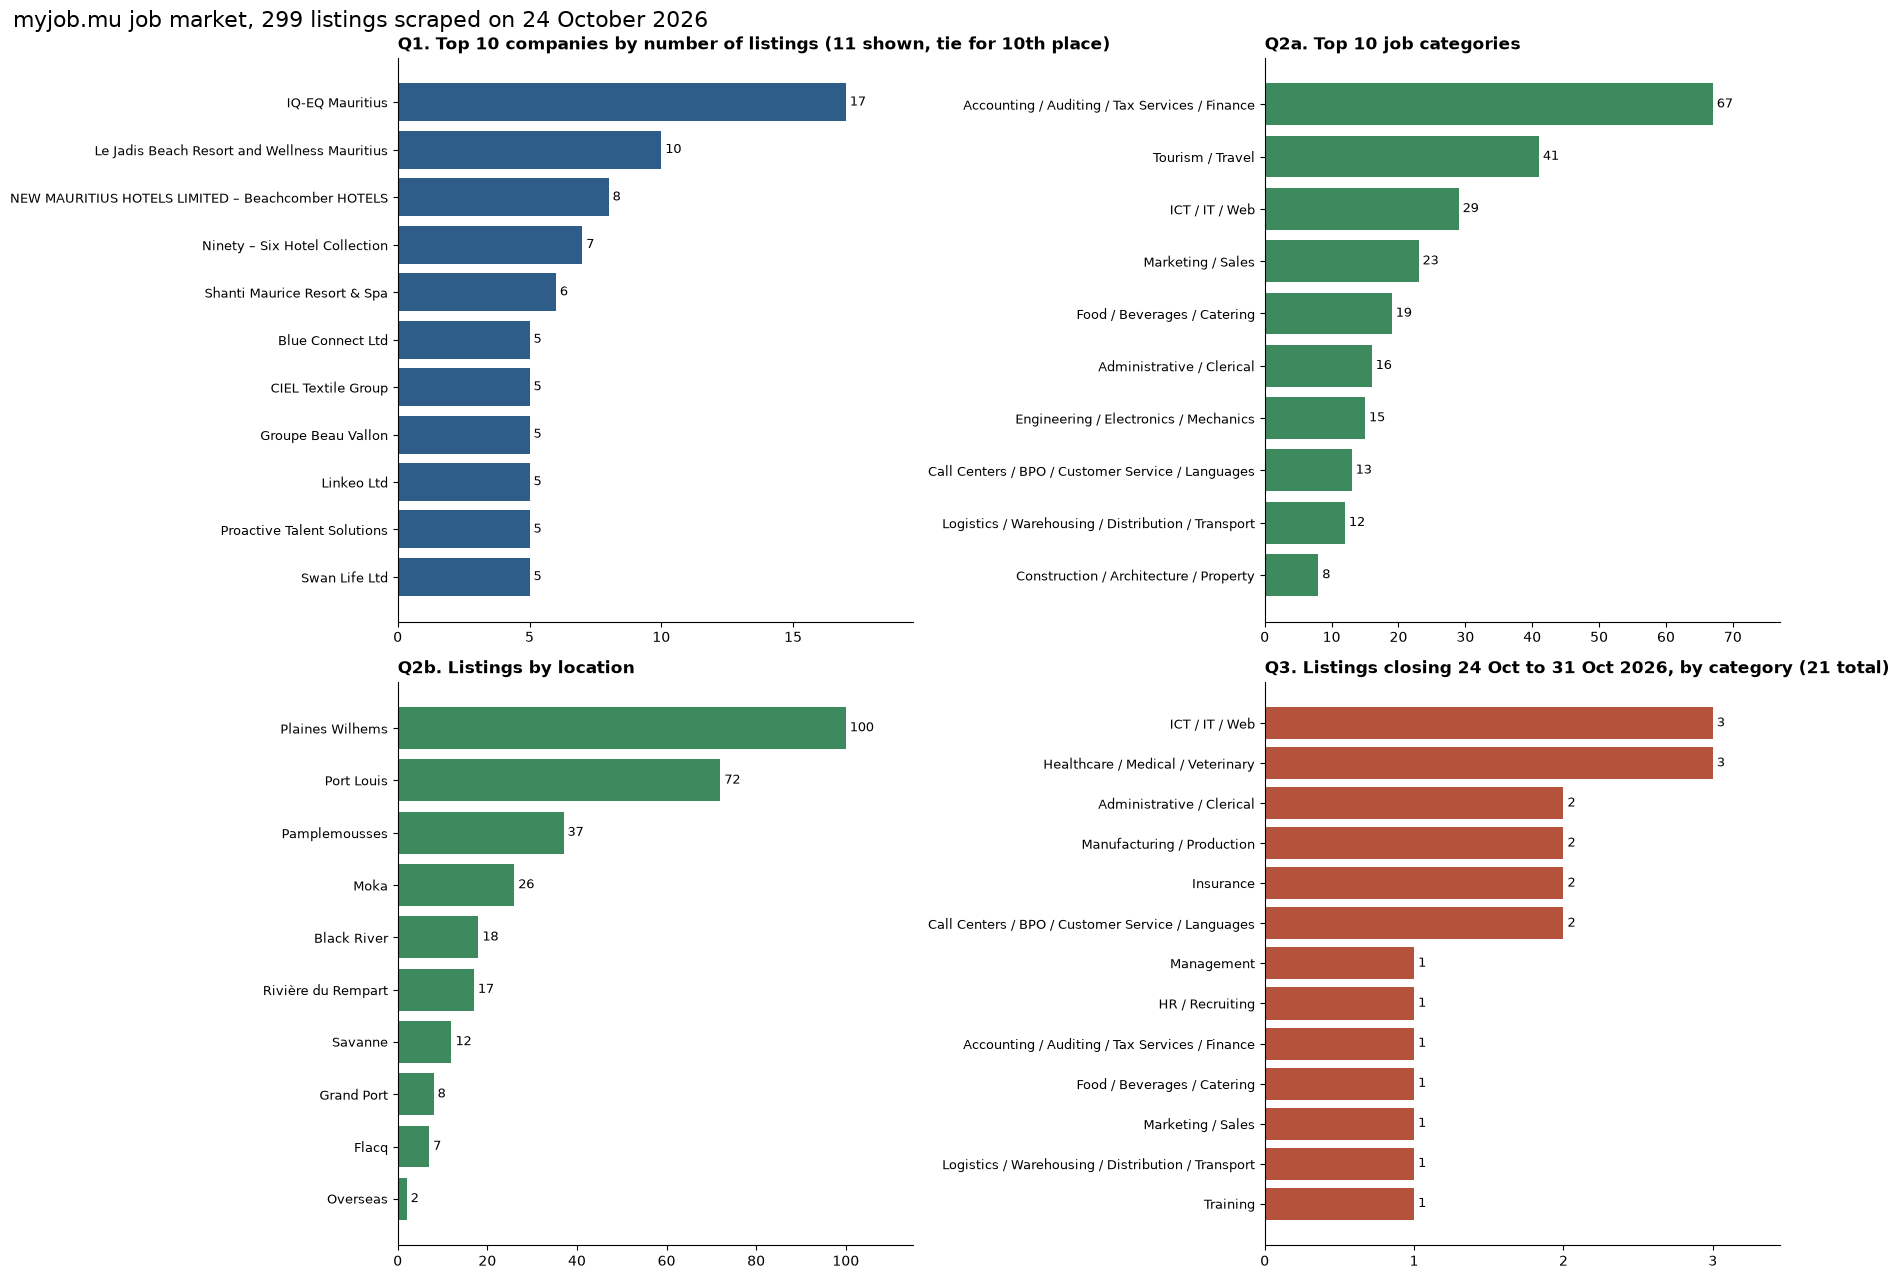

In [6]:
def barh(ax, s, title, color):
    s = s.iloc[::-1]
    ax.barh(s.index, s.values, color=color)
    for y, v in enumerate(s.values):
        ax.text(v, y, f' {v}', va='center', fontsize=9)
    ax.set_title(title, loc='left', fontsize=12, fontweight='bold')
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(axis='y', labelsize=9)
    ax.set_xlim(0, s.max() * 1.15)
    ax.xaxis.get_major_locator().set_params(integer=True)


fig, axes = plt.subplots(2, 2, figsize=(18, 13))
q1_title = 'Q1. Top 10 companies by number of listings'
if len(top_companies) > 10:
    q1_title += f' ({len(top_companies)} shown, tie for 10th place)'
barh(axes[0, 0], top_companies, q1_title, '#2f5d8a')
barh(axes[0, 1], by_category.head(10), 'Q2a. Top 10 job categories', '#3d8a5f')
barh(axes[1, 0], by_location, 'Q2b. Listings by location', '#3d8a5f')
barh(axes[1, 1], closing_by_category,
     f'Q3. Listings closing {AS_OF:%d %b} to {WEEK_END:%d %b %Y}, by category ({len(closing_soon)} total)', '#b5523b')
fig.suptitle(f'myjob.mu job market, {len(df)} listings scraped on {AS_OF:%d %B %Y}', fontsize=16, x=0.01, ha='left')
fig.tight_layout()
fig.savefig('Task3_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()